In [5]:
import sys
from pathlib import Path
RACINE = Path("..").resolve()
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd

RENOMMAGE = {
    "person_age": "age_ans",
    "person_income": "revenu_annuel",
    "person_home_ownership": "statut_logement",
    "person_emp_length": "anciennete_emploi_ans",
    "loan_intent": "objet_credit",
    "loan_amnt": "montant_credit",
    "loan_status": "defaut",
    "loan_percent_income": "credit_sur_revenu",
    "cb_person_default_on_file": "defaut_anterieur",
    "cb_person_cred_hist_length": "anciennete_historique_ans",
}

cr = pd.read_parquet(RACINE / "data" / "processed" / "credit_risk_clean.parquet")
cr = cr.rename(columns=RENOMMAGE)
print(cr.shape, "taux de défaut :", cr["defaut"].mean().round(4))

(32409, 10) taux de défaut : 0.2187


In [6]:
for col in ["statut_logement", "objet_credit", "defaut_anterieur"]:
    t = cr.groupby(col)["defaut"].agg(["size", "mean"]).round(3)
    t.columns = ["n", "taux_defaut"]
    print(t, "\n")

                     n  taux_defaut
statut_logement                    
MORTGAGE         13366        0.126
OTHER              106        0.311
OWN               2563        0.075
RENT             16374        0.316 

                      n  taux_defaut
objet_credit                        
DEBTCONSOLIDATION  5189        0.287
EDUCATION          6409        0.173
HOMEIMPROVEMENT    3594        0.262
MEDICAL            6042        0.268
PERSONAL           5496        0.199
VENTURE            5679        0.149 

                      n  taux_defaut
defaut_anterieur                    
N                 26680        0.184
Y                  5729        0.379 



In [7]:
for col in ["age_ans", "anciennete_emploi_ans",
            "anciennete_historique_ans", "credit_sur_revenu"]:
    tranche = pd.qcut(cr[col], 6, duplicates="drop")
    t = cr.groupby(tranche, observed=True)["defaut"].agg(["size", "mean"]).round(3)
    t.columns = ["n", "taux_defaut"]
    print(col, "\n", t, "\n")

age_ans 
                    n  taux_defaut
age_ans                          
(19.999, 23.0]  8694        0.240
(23.0, 24.0]    3526        0.218
(24.0, 26.0]    5485        0.217
(26.0, 28.0]    3975        0.215
(28.0, 33.0]    5947        0.202
(33.0, 94.0]    4782        0.207 

anciennete_emploi_ans 
                           n  taux_defaut
anciennete_emploi_ans                   
(-0.001, 1.0]          6983        0.279
(1.0, 2.0]             3831        0.258
(2.0, 4.0]             6303        0.207
(4.0, 6.0]             5578        0.188
(6.0, 8.0]             3861        0.179
(8.0, 41.0]            4966        0.168 

anciennete_historique_ans 
                                n  taux_defaut
anciennete_historique_ans                    
(1.999, 3.0]               11826        0.230
(3.0, 4.0]                  5879        0.224
(4.0, 7.0]                  5622        0.204
(7.0, 9.0]                  3781        0.211
(9.0, 30.0]                 5301        0.208 

credit_sur

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUM = ["age_ans", "anciennete_emploi_ans", "anciennete_historique_ans", "credit_sur_revenu"]
CAT = ["statut_logement", "objet_credit", "defaut_anterieur"]

X, y = cr[NUM + CAT], cr["defaut"]
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42)
for nom, cible in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(nom, len(cible), "défaut", cible.mean().round(4))


def preprocesseur():
    numerique = Pipeline([("imputation", SimpleImputer(strategy="median")),
                          ("echelle", StandardScaler())])
    return ColumnTransformer([
        ("num", numerique, NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])


regression = Pipeline([("prep", preprocesseur()),
                       ("modele", LogisticRegression(max_iter=1000))])
regression.fit(X_train, y_train)
auc_val = roc_auc_score(y_val, regression.predict_proba(X_val)[:, 1])
print("AUC validation, régression logistique :", round(auc_val, 4))

train 19445 défaut 0.2187
val 6482 défaut 0.2188
test 6482 défaut 0.2188
AUC validation, régression logistique : 0.7946


In [9]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


def auc_validation(modele):
    modele.fit(X_train, y_train)
    return round(roc_auc_score(y_val, modele.predict_proba(X_val)[:, 1]), 4)


foret = Pipeline([("prep", preprocesseur()),
                  ("modele", RandomForestClassifier(
                      n_estimators=300, min_samples_leaf=20,
                      n_jobs=-1, random_state=42))])

xgb_libre = Pipeline([("prep", preprocesseur()),
                      ("modele", XGBClassifier(
                          n_estimators=300, learning_rate=0.05, max_depth=4,
                          tree_method="hist", n_jobs=-1, random_state=42))])

print("Forêt aléatoire :", auc_validation(foret))
print("XGBoost libre   :", auc_validation(xgb_libre))

Forêt aléatoire : 0.8187
XGBoost libre   : 0.823


In [10]:
prep = preprocesseur().fit(X_train)
Xt, Xv = prep.transform(X_train), prep.transform(X_val)

resultats = []
for profondeur in [3, 4, 5, 6]:
    for poids_min in [1, 10]:
        modele = XGBClassifier(
            n_estimators=2000, learning_rate=0.05, max_depth=profondeur,
            min_child_weight=poids_min, subsample=0.8, colsample_bytree=0.8,
            tree_method="hist", n_jobs=-1, random_state=42,
            eval_metric="auc", early_stopping_rounds=50)
        modele.fit(Xt, y_train, eval_set=[(Xv, y_val)], verbose=False)
        resultats.append({"profondeur": profondeur, "min_child_weight": poids_min,
                          "arbres": modele.best_iteration + 1,
                          "auc_validation": round(modele.best_score, 4)})

print(pd.DataFrame(resultats).sort_values("auc_validation", ascending=False).to_string(index=False))

 profondeur  min_child_weight  arbres  auc_validation
          4                 1     158          0.8256
          5                 1     120          0.8251
          5                10     222          0.8249
          3                 1     242          0.8248
          4                10     259          0.8245
          6                 1      92          0.8244
          6                10      94          0.8244
          3                10     228          0.8243


In [11]:
def entrainer(num, cat, monotone_sur=None):
    transf = ColumnTransformer([
        ("num", Pipeline([("imputation", SimpleImputer(strategy="median")),
                          ("echelle", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    Xt = transf.fit_transform(X_train[num + cat])
    Xv = transf.transform(X_val[num + cat])

    contraintes = None
    if monotone_sur:
        contraintes = [0] * Xt.shape[1]
        contraintes[num.index(monotone_sur)] = 1     # 1 = effet croissant imposé
        contraintes = tuple(contraintes)

    modele = XGBClassifier(
        n_estimators=2000, learning_rate=0.05, max_depth=4, min_child_weight=10,
        subsample=0.8, colsample_bytree=0.8, monotone_constraints=contraintes,
        tree_method="hist", n_jobs=-1, random_state=42,
        eval_metric="auc", early_stopping_rounds=50)
    modele.fit(Xt, y_train, eval_set=[(Xv, y_val)], verbose=False)
    return round(modele.best_score, 4), modele.best_iteration + 1


sans_antecedent = [c for c in CAT if c != "defaut_anterieur"]
sans_historique = [c for c in NUM if c != "anciennete_historique_ans"]
scenarios = {
    "Toutes les variables, sans contrainte": (NUM, CAT, None),
    "Toutes les variables, contrainte monotone": (NUM, CAT, "credit_sur_revenu"),
    "Sans antécédent de défaut": (NUM, sans_antecedent, "credit_sur_revenu"),
    "Sans antécédent ni historique": (sans_historique, sans_antecedent, "credit_sur_revenu"),
}
for nom, (n, c, m) in scenarios.items():
    auc, arbres = entrainer(n, c, m)
    print(f"{nom:<45} AUC {auc}  ({arbres} arbres)")

Toutes les variables, sans contrainte         AUC 0.8245  (259 arbres)
Toutes les variables, contrainte monotone     AUC 0.8263  (255 arbres)
Sans antécédent de défaut                     AUC 0.8029  (283 arbres)
Sans antécédent ni historique                 AUC 0.8038  (299 arbres)


In [12]:
noms = regression.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(regression.named_steps["modele"].coef_[0], index=noms)
rapport = np.exp(coefs["cat__defaut_anterieur_Y"] - coefs["cat__defaut_anterieur_N"])
print("Rapport de cotes de l'antécédent de défaut, toutes choses égales :", round(rapport, 2))

Rapport de cotes de l'antécédent de défaut, toutes choses égales : 2.83


In [13]:
from sklearn.metrics import average_precision_score, brier_score_loss, roc_curve

transf = preprocesseur().fit(X_train)
Xt, Xte = transf.transform(X_train), transf.transform(X_test)
contraintes = [0] * Xt.shape[1]
contraintes[NUM.index("credit_sur_revenu")] = 1

final = XGBClassifier(
    n_estimators=255, learning_rate=0.05, max_depth=4, min_child_weight=10,
    subsample=0.8, colsample_bytree=0.8, monotone_constraints=tuple(contraintes),
    tree_method="hist", n_jobs=-1, random_state=42)
final.fit(Xt, y_train)
p = final.predict_proba(Xte)[:, 1]

fpr, tpr, _ = roc_curve(y_test, p)
print("AUC test      :", round(roc_auc_score(y_test, p), 4))
print("PR-AUC test   :", round(average_precision_score(y_test, p), 4))
print("KS test       :", round((tpr - fpr).max(), 4))
print("Brier test    :", round(brier_score_loss(y_test, p), 4))

d = pd.DataFrame({"p": p, "y": y_test.values})
d["decile"] = pd.qcut(d["p"], 10, labels=False, duplicates="drop") + 1
print(d.groupby("decile").agg(n=("y", "size"), prevu=("p", "mean"),
                              observe=("y", "mean")).round(3))

AUC test      : 0.8361
PR-AUC test   : 0.7219
KS test       : 0.5162
Brier test    : 0.1044
          n  prevu  observe
decile                     
1       649  0.017    0.018
2       648  0.047    0.049
3       648  0.071    0.066
4       648  0.094    0.116
5       648  0.116    0.120
6       648  0.139    0.151
7       648  0.172    0.140
8       648  0.230    0.210
9       648  0.380    0.409
10      649  0.891    0.906


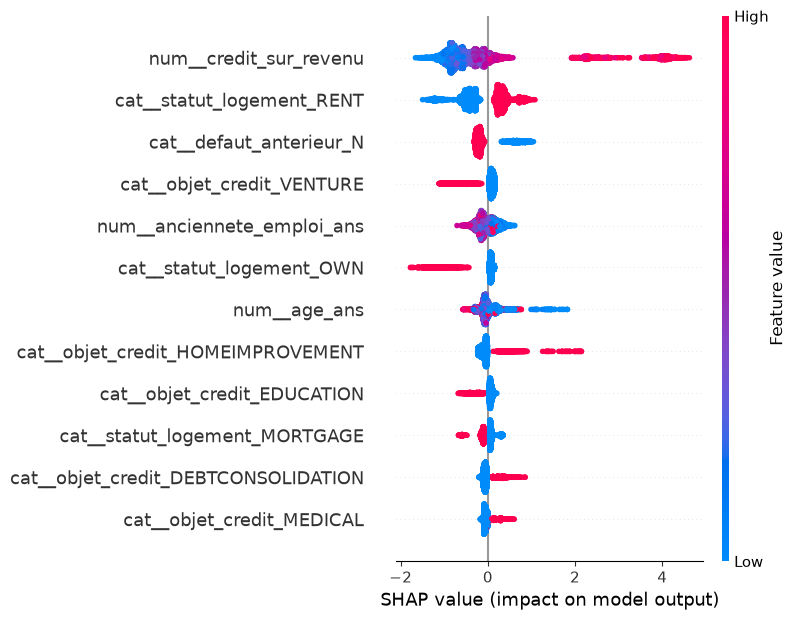

In [14]:
import shap

noms = transf.get_feature_names_out()
Xv = transf.transform(X_val)
Xv = Xv.toarray() if hasattr(Xv, "toarray") else Xv
valeurs = shap.TreeExplainer(final).shap_values(Xv)
shap.summary_plot(valeurs, Xv, feature_names=noms, max_display=12)